# 04 — Model Development

Compare Logistic Regression and Random Forest with 5-fold stratified CV. Feature selection and preprocessing are learned inside each training fold. Select the model by CV average precision, then select the threshold on validation. Save the same train-fitted model without refitting on validation.

In [1]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
MODEL_DIR = PROJECT_ROOT / "models"
pd.set_option("display.max_columns", None)

In [2]:
from src.modeling.train import train_models
comparison, metadata, threshold_table = train_models()
display(comparison)
print(json.dumps(metadata, indent=2, ensure_ascii=False))

Training logistic_regression...


CV PR-AUC: 0.2130


Training random_forest...


CV PR-AUC: 0.2316


Selected random_forest; threshold=0.4021


,model,cv_pr_auc,cv_pr_auc_std,cv_train_pr_auc,cv_roc_auc,best_parameters
0,random_forest,0.231625,0.063169,0.588425,0.840031,"{'model__n_estimators': 200, 'model__min_sampl..."
1,logistic_regression,0.213043,0.015788,0.216771,0.852034,{'model__C': 0.01}


{
  "model_name": "random_forest",
  "task": "binary_classification",
  "target": "stroke",
  "labels": {
    "0": "no stroke",
    "1": "stroke"
  },
  "selection_metric": "average_precision (PR-AUC)",
  "train_cv_pr_auc": 0.23162460218835007,
  "train_cv_pr_auc_std": 0.06316921626873069,
  "validation_pr_auc": 0.267957393310515,
  "validation_roc_auc": 0.8500722945167389,
  "threshold": 0.40211028377095137,
  "threshold_reason": "highest validation precision with recall >= 80%",
  "training_rows": 3577,
  "validation_rows": 766,
  "refit_on_validation": false,
  "selected_logical_features": [
    "age",
    "heart_disease",
    "ever_married",
    "work_type",
    "bmi",
    "age_squared",
    "bmi_squared",
    "age_glucose_interaction",
    "bmi_glucose_interaction",
    "comorbidity_count"
  ],
  "required_raw_features": [
    "age",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "avg_glucose_level",
    "bmi"
  ],
  "best_parameters": {
    "mod

## Validation and the decision threshold

Recall 80% is a project assumption. The classifier scores are not calibrated medical risk probabilities. Test is not used for choosing the model or threshold.

              precision    recall  f1-score   support

           0     0.9892    0.7503    0.8534       729
           1     0.1455    0.8378    0.2480        37

    accuracy                         0.7546       766
   macro avg     0.5673    0.7941    0.5507       766
weighted avg     0.9484    0.7546    0.8241       766



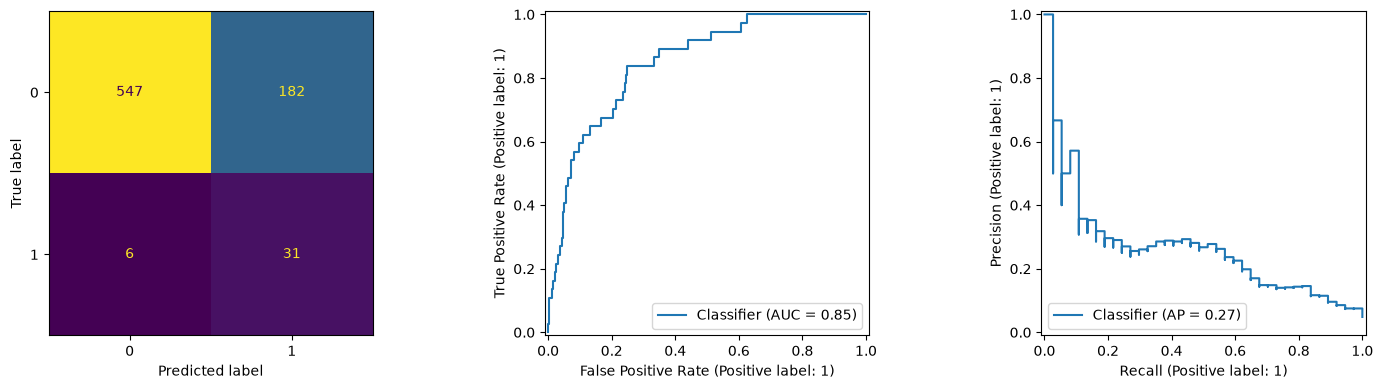

In [3]:
import joblib
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, classification_report
from src.modeling.pipeline import split_features_target

bundle = joblib.load(MODEL_DIR / "final_model_bundle.joblib")
validation_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "validation.csv")
X_validation, y_validation = split_features_target(validation_df)
validation_probability = bundle["pipeline"].predict_proba(X_validation[bundle["required_raw_features"]])[:, 1]
validation_prediction = (validation_probability >= bundle["threshold"]).astype(int)
print(classification_report(y_validation, validation_prediction, digits=4, zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_validation, validation_prediction, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_validation, validation_probability, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_validation, validation_probability, ax=axes[2])
plt.tight_layout()
plt.show()

In [4]:
manifest = json.loads((MODEL_DIR / "feature_manifest.json").read_text(encoding="utf-8"))
print("Selected logical features:", manifest["selected_logical_features"])
print("Required raw inputs:", manifest["required_raw_features"])
display(pd.DataFrame(manifest["feature_scores"]))

Selected logical features: ['age', 'heart_disease', 'ever_married', 'work_type', 'bmi', 'age_squared', 'bmi_squared', 'age_glucose_interaction', 'bmi_glucose_interaction', 'comorbidity_count']
Required raw inputs: ['age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'avg_glucose_level', 'bmi']


,feature,mi_score,selected
0,age,0.042639,True
1,age_squared,0.040877,True
2,age_glucose_interaction,0.027025,True
3,bmi_glucose_interaction,0.016590,True
4,bmi,0.010729,True
5,comorbidity_count,0.010612,True
6,bmi_squared,0.008000,True
7,ever_married,0.007677,True
8,work_type,0.007493,True
9,heart_disease,0.006403,True
